# Missing Value Handling

## Introduction

Missing values are one of the common problems in real-world datasets.

A missing value occurs when some information is not available in a particular row or column.

Missing values can affect data analysis and machine learning model performance.

In this notebook, we will learn how to identify, analyze, and handle missing values using Python and Pandas.

## Objectives

- Understand different types of missing values.
- Identify missing values in a dataset.
- Calculate missing value percentages.
- Understand different techniques to handle missing values.
- Implement missing value handling using Pandas and Scikit-learn.
- Compare the dataset before and after handling missing values.

## 1. What are Missing Values?

Missing values are data points that are not available or recorded in a dataset.

For example, consider a student dataset where the age or marks of some students are not entered.

These empty values are called missing values.

In Pandas, missing values are commonly represented as:
- NaN – Not a Number
- None – No value
- NaT – Not a Time (for date/time data)

### Why do missing values occur?

- Data entry mistakes.
- Incomplete forms.
- Errors while collecting data.
- Sensor or system failures.
- Information not provided by users.

### Example

If a student's marks are not recorded, the Marks column will contain a missing value.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Creating a Sample Dataset

We will create a sample student dataset containing missing values.

This dataset includes student details such as age, gender, department, study hours, marks, and attendance.

We will use this dataset to practice different missing value handling techniques.

In [2]:
data = {
    "Student_ID": [101, 102, 103, 104, 105, 106, 107, 108, 109, 110],
    "Name": ["Asha", "Rahul", "Priya", "Kiran", "Sneha",
             "Arun", "Meena", "Ravi", "Pooja", "Anil"],
    "Age": [20, 21, np.nan, 22, 23, np.nan, 21, 24, 22, 20],
    "Gender": ["Female", "Male", "Female", np.nan, "Female",
               "Male", "Female", "Male", np.nan, "Male"],
    "Department": ["AI", "CS", "AI", "EC", np.nan,
                   "CS", "AI", "EC", "CS", "AI"],
    "Study_Hours": [3, 5, 4, np.nan, 6, 2, np.nan, 5, 4, 3],
    "Marks": [75, 82, np.nan, 68, 90, 55, 78, np.nan, 85, 72],
    "Attendance": [90, 85, 88, 75, np.nan, 80, 92, 70, np.nan, 95]
}

df = pd.DataFrame(data)

df

,Student_ID,Name,Age,Gender,Department,Study_Hours,Marks,Attendance
0,101,Asha,20.0,Female,AI,3.0,75.0,90.0
1,102,Rahul,21.0,Male,CS,5.0,82.0,85.0
2,103,Priya,NaN,Female,AI,4.0,NaN,88.0
3,104,Kiran,22.0,NaN,EC,NaN,68.0,75.0
4,105,Sneha,23.0,Female,NaN,6.0,90.0,NaN
5,106,Arun,NaN,Male,CS,2.0,55.0,80.0
6,107,Meena,21.0,Female,AI,NaN,78.0,92.0
7,108,Ravi,24.0,Male,EC,5.0,NaN,70.0
8,109,Pooja,22.0,NaN,CS,4.0,85.0,NaN
9,110,Anil,20.0,Male,AI,3.0,72.0,95.0


## 3. Understanding the Dataset

Before handling missing values, we should understand the dataset.

We can use:
- head() – Displays the first five rows.
- shape – Displays the number of rows and columns.
- info() – Displays column names and data types.
- isnull() – Identifies missing values.

In [3]:
print("First five rows:")
display(df.head())

print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

First five rows:


,Student_ID,Name,Age,Gender,Department,Study_Hours,Marks,Attendance
0,101,Asha,20.0,Female,AI,3.0,75.0,90.0
1,102,Rahul,21.0,Male,CS,5.0,82.0,85.0
2,103,Priya,NaN,Female,AI,4.0,NaN,88.0
3,104,Kiran,22.0,NaN,EC,NaN,68.0,75.0
4,105,Sneha,23.0,Female,NaN,6.0,90.0,NaN


Dataset shape: (10, 8)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Student_ID   10 non-null     int64  
 1   Name         10 non-null     str    
 2   Age          8 non-null      float64
 3   Gender       8 non-null      str    
 4   Department   9 non-null      str    
 5   Study_Hours  8 non-null      float64
 6   Marks        8 non-null      float64
 7   Attendance   8 non-null      float64
dtypes: float64(4), int64(1), str(3)
memory usage: 880.0 bytes


## 4. Types of Missing Values

There are three important types of missing values.

### 1. MCAR – Missing Completely At Random

Missing values occur randomly and are not related to any other data.

Example:
A few student attendance records are accidentally lost because of a system error.

### 2. MAR – Missing At Random

Missing values depend on another available variable in the dataset.

Example:
Students from a particular department may be more likely to leave the study hours field empty.

### 3. MNAR – Missing Not At Random

Missing values depend on the missing value itself or an unobserved reason.

Example:
Students who scored very low marks may choose not to report their marks.

### Difference

- MCAR: Missingness is unrelated to the data.
- MAR: Missingness depends on other observed data.
- MNAR: Missingness depends on the missing value itself or an unobserved factor.

Note: These patterns cannot always be identified just by looking at NaN values. Domain knowledge and further analysis may be required.

## 5. Identifying Missing Values

Pandas provides the isnull() and isna() functions to identify missing values.

- isnull() returns True for missing values.
- notnull() returns True for available values.
- sum() counts the missing values in each column.

In [4]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values in each column:
Student_ID     0
Name           0
Age            2
Gender         2
Department     1
Study_Hours    2
Marks          2
Attendance     2
dtype: int64

Total missing values:
11


## 6. Missing Value Percentage

Counting missing values is not always enough.

We should also calculate the percentage of missing values in each column.

Formula:

Missing Percentage = (Number of Missing Values / Total Rows) * 100

This helps us understand how much information is missing from each column.

In [5]:
missing_count = df.isnull().sum()

missing_percentage = (missing_count / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

missing_summary

,Missing_Count,Missing_Percentage
Student_ID,0,0.0
Name,0,0.0
Age,2,20.0
Gender,2,20.0
Department,1,10.0
Study_Hours,2,20.0
Marks,2,20.0
Attendance,2,20.0


## 7. Visualizing Missing Values

A bar chart helps us understand which columns contain more missing values.

This makes it easier to identify columns that need attention.

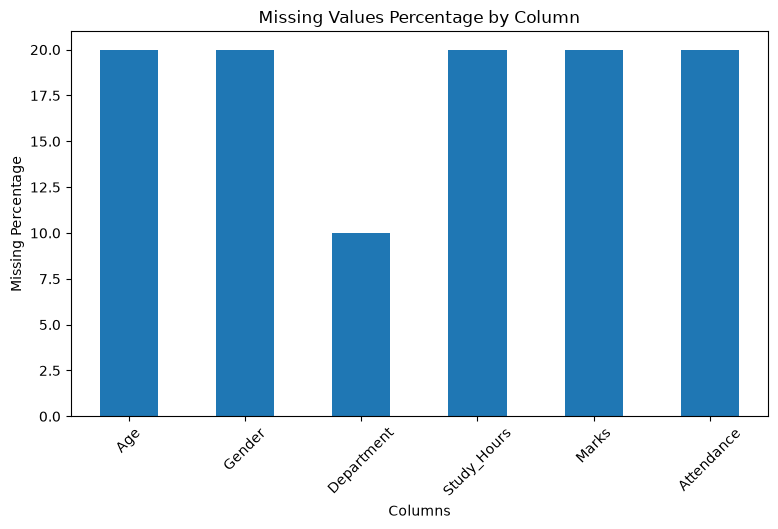

In [6]:
missing_percentage[missing_percentage > 0].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Missing Values Percentage by Column")
plt.xlabel("Columns")
plt.ylabel("Missing Percentage")
plt.xticks(rotation=45)
plt.show()

## 8. Techniques for Handling Missing Values

There are different techniques for handling missing values.

### 1. Removing missing values

- dropna() removes rows or columns containing missing values.
- It is useful when only a small amount of data is missing and removing it is reasonable.

### 2. Mean Imputation

- Replaces missing numerical values with the average.
- Suitable when the data does not contain strong outliers.

### 3. Median Imputation

- Replaces missing numerical values with the middle value.
- Useful when the data contains outliers or is skewed.

### 4. Mode Imputation

- Replaces missing values with the most frequently occurring value.
- Commonly used for categorical columns.

### 5. Constant Value Imputation

- Replaces missing values with a fixed value such as 0 or "Unknown".

### 6. Forward Fill

- Uses the previous available value to fill a missing value.

### 7. Backward Fill

- Uses the next available value to fill a missing value.

### 8. Interpolation

- Estimates missing numerical values using surrounding values.

### 9. Group-Based Imputation

- Fills missing values using the mean or median of a particular group.

### 10. KNN and Iterative Imputation

- KNN uses similar records to estimate missing values.
- Iterative Imputation estimates missing values using relationships between other features.

In [7]:
# Create a copy of the original dataset
drop_df = df.copy()

# Remove rows containing missing values
removed_rows = drop_df.dropna()

print("Original shape:", drop_df.shape)
print("Shape after removing missing rows:", removed_rows.shape)

display(removed_rows)

Original shape: (10, 8)
Shape after removing missing rows: (3, 8)


,Student_ID,Name,Age,Gender,Department,Study_Hours,Marks,Attendance
0,101,Asha,20.0,Female,AI,3.0,75.0,90.0
1,102,Rahul,21.0,Male,CS,5.0,82.0,85.0
9,110,Anil,20.0,Male,AI,3.0,72.0,95.0


### Observation

The dropna() function removes rows that contain at least one missing value by default.

Removing too many rows can result in loss of useful information.

Therefore, we should analyze missing values before deciding to remove records.

## 9. Mean Imputation

Mean imputation replaces missing numerical values with the average of the available values.

Formula:

Mean = Sum of Values / Number of Values

We will use the mean to fill missing values in the Age column.

In [8]:
median_df = df.copy()

marks_median = median_df["Marks"].median()

median_df["Marks"] = median_df["Marks"].fillna(marks_median)

print("Marks median:", marks_median)

print("\nMarks column after median imputation:")
print(median_df["Marks"])

Marks median: 76.5

Marks column after median imputation:
0    75.0
1    82.0
2    76.5
3    68.0
4    90.0
5    55.0
6    78.0
7    76.5
8    85.0
9    72.0
Name: Marks, dtype: float64


## 11. Mode Imputation

Mode is the value that appears most frequently in a column.

It is commonly used to fill missing categorical values.

We will fill missing values in the Gender column using its mode.

In [9]:
mode_df = df.copy()

gender_mode = mode_df["Gender"].mode()[0]

mode_df["Gender"] = mode_df["Gender"].fillna(gender_mode)

print("Gender mode:", gender_mode)

print("\nGender column after mode imputation:")
print(mode_df["Gender"])

Gender mode: Female

Gender column after mode imputation:
0    Female
1      Male
2    Female
3    Female
4    Female
5      Male
6    Female
7      Male
8    Female
9      Male
Name: Gender, dtype: str


## 12. Constant Value Imputation

In this method, missing values are replaced with a fixed value.

For categorical columns, we can use "Unknown".

This is useful when we do not want to guess the missing category.

In [10]:
constant_df = df.copy()

constant_df["Department"] = constant_df["Department"].fillna("Unknown")

print("Department column after constant imputation:")
print(constant_df["Department"])

Department column after constant imputation:
0         AI
1         CS
2         AI
3         EC
4    Unknown
5         CS
6         AI
7         EC
8         CS
9         AI
Name: Department, dtype: str


## 13. Forward Fill and Backward Fill

### Forward Fill (ffill)

Forward fill replaces a missing value with the previous available value.

### Backward Fill (bfill)

Backward fill replaces a missing value with the next available value.

These methods are useful for ordered data, such as time-series records.

We will demonstrate them using the Study_Hours column.

In [11]:
fill_df = df.copy()

fill_df["Forward_Fill"] = fill_df["Study_Hours"].ffill()

fill_df["Backward_Fill"] = fill_df["Study_Hours"].bfill()

display(fill_df[[
    "Study_Hours",
    "Forward_Fill",
    "Backward_Fill"
]])

,Study_Hours,Forward_Fill,Backward_Fill
0,3.0,3.0,3.0
1,5.0,5.0,5.0
2,4.0,4.0,4.0
3,NaN,4.0,6.0
4,6.0,6.0,6.0
5,2.0,2.0,2.0
6,NaN,2.0,5.0
7,5.0,5.0,5.0
8,4.0,4.0,4.0
9,3.0,3.0,3.0


## 14. Interpolation

Interpolation estimates missing numerical values using nearby available values.

For example, if a sequence contains 10, NaN, and 30, linear interpolation estimates the missing value as 20.

It is commonly used for numerical and time-series data.

In [12]:
interpolation_df = df.copy()

interpolation_df["Study_Hours"] = (
    interpolation_df["Study_Hours"].interpolate(method="linear")
)

print("Study hours after interpolation:")
print(interpolation_df["Study_Hours"])

Study hours after interpolation:
0    3.0
1    5.0
2    4.0
3    5.0
4    6.0
5    2.0
6    3.5
7    5.0
8    4.0
9    3.0
Name: Study_Hours, dtype: float64


## 15. Group-Based Imputation

In group-based imputation, missing values are filled using information from the same group.

For example, missing marks can be filled using the median marks of students from the same department.

This method can preserve differences between groups better than using one overall value.

In [13]:
group_df = df.copy()

group_medians = group_df.groupby("Department")["Marks"].transform("median")

group_df["Marks"] = group_df["Marks"].fillna(group_medians)

print("Marks after group-based imputation:")
display(group_df[["Department", "Marks"]])

Marks after group-based imputation:


,Department,Marks
0,AI,75.0
1,CS,82.0
2,AI,75.0
3,EC,68.0
4,NaN,90.0
5,CS,55.0
6,AI,78.0
7,EC,68.0
8,CS,85.0
9,AI,72.0


In [14]:
group_df = df.copy()

group_medians = group_df.groupby("Department")["Marks"].transform("median")

group_df["Marks"] = group_df["Marks"].fillna(group_medians)

overall_median = group_df["Marks"].median()

group_df["Marks"] = group_df["Marks"].fillna(overall_median)

print("Remaining missing marks:", group_df["Marks"].isnull().sum())

Remaining missing marks: 0


## 16. KNN Imputation

KNN stands for K-Nearest Neighbors.

KNN imputation fills missing values by looking at similar records in the dataset.

It finds the nearest records based on available numerical features and uses their values to estimate missing data.

It is useful when different features have relationships with each other.

We will use KNNImputer from Scikit-learn.

In [15]:
from sklearn.impute import KNNImputer

knn_df = df.copy()

numeric_columns = [
    "Age",
    "Study_Hours",
    "Marks",
    "Attendance"
]

imputer = KNNImputer(n_neighbors=3)

knn_df[numeric_columns] = imputer.fit_transform(
    knn_df[numeric_columns]
)

print("Dataset after KNN imputation:")
display(knn_df[numeric_columns])

print("\nRemaining missing values:")
print(knn_df[numeric_columns].isnull().sum())

Dataset after KNN imputation:


,Age,Study_Hours,Marks,Attendance
0,20.000000,3.000000,75.000000,90.0
1,21.000000,5.000000,82.000000,85.0
2,21.666667,4.000000,83.333333,88.0
3,22.000000,3.333333,68.000000,75.0
4,23.000000,6.000000,90.000000,81.0
5,22.000000,2.000000,55.000000,80.0
6,21.000000,3.333333,78.000000,92.0
7,24.000000,5.000000,81.000000,70.0
8,22.000000,4.000000,85.000000,81.0
9,20.000000,3.000000,72.000000,95.0



Remaining missing values:
Age            0
Study_Hours    0
Marks          0
Attendance     0
dtype: int64


### Observation

KNNImputer uses nearby records to estimate missing numerical values.

The n_neighbors=3 setting means it considers three neighboring records.

For real-world datasets, numerical features may need scaling before KNN imputation because features with larger numeric ranges can influence distance calculations more strongly.

## 17. Iterative Imputation

Iterative imputation estimates missing values by using relationships between different columns.

It works by treating each column with missing values as a target and predicting its missing values using other columns.

This process is repeated several times to improve the estimates.

We will use IterativeImputer from Scikit-learn.

In [17]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

iterative_df = df.copy()

iterative_imputer = IterativeImputer(
    max_iter=10,
    random_state=42
)

iterative_df[numeric_columns] = iterative_imputer.fit_transform(
    iterative_df[numeric_columns]
)

print("Dataset after Iterative Imputation:")
display(iterative_df[numeric_columns])

print("\nRemaining missing values:")
print(iterative_df[numeric_columns].isnull().sum())

Dataset after Iterative Imputation:


,Age,Study_Hours,Marks,Attendance
0,20.000000,3.000000,75.000000,90.000000
1,21.000000,5.000000,82.000000,85.000000
2,21.192034,4.000000,79.230684,88.000000
3,22.000000,3.683855,68.000000,75.000000
4,23.000000,6.000000,90.000000,79.173117
5,20.580401,2.000000,55.000000,80.000000
6,21.000000,3.585377,78.000000,92.000000
7,24.000000,5.000000,78.922402,70.000000
8,22.000000,4.000000,85.000000,88.297972
9,20.000000,3.000000,72.000000,95.000000



Remaining missing values:
Age            0
Study_Hours    0
Marks          0
Attendance     0
dtype: int64


### Observation

IterativeImputer estimates missing values by learning relationships between numerical columns.

It can be useful when numerical features are related to each other.

However, the estimated values may not always be accurate. We should validate the results before using them for machine learning.

## 18. Comparing Different Imputation Methods

Different imputation techniques are suitable for different types of data.

| Method | Suitable Use |
|---|---|
| Mean | Numerical data without strong outliers |
| Median | Numerical data with outliers or skewness |
| Mode | Categorical data |
| Constant | Unknown or fixed replacement |
| Forward Fill | Ordered or time-series data |
| Backward Fill | Ordered or time-series data |
| Interpolation | Numerical sequences |
| Group-Based | Data with meaningful groups |
| KNN | Related numerical features |
| Iterative | Numerical features with relationships |

There is no single best method for every dataset.

The correct method depends on the data, missingness pattern, and business requirements.

## 19. Complete Missing Value Handling

Now we will apply suitable techniques to create a cleaned version of our sample dataset.

- Age: Median imputation.
- Gender: Mode imputation.
- Department: Constant value imputation.
- Study_Hours: Median imputation.
- Marks: Median imputation.
- Attendance: Median imputation.

We are using separate copies so that the original dataset remains unchanged.

In [18]:
clean_df = df.copy()

# Fill numerical missing values using median
numerical_columns = [
    "Age",
    "Study_Hours",
    "Marks",
    "Attendance"
]

for column in numerical_columns:
    clean_df[column] = clean_df[column].fillna(
        clean_df[column].median()
    )

# Fill categorical missing values
clean_df["Gender"] = clean_df["Gender"].fillna(
    clean_df["Gender"].mode()[0]
)

clean_df["Department"] = clean_df["Department"].fillna("Unknown")

print("Cleaned dataset:")
display(clean_df)

Cleaned dataset:


,Student_ID,Name,Age,Gender,Department,Study_Hours,Marks,Attendance
0,101,Asha,20.0,Female,AI,3.0,75.0,90.0
1,102,Rahul,21.0,Male,CS,5.0,82.0,85.0
2,103,Priya,21.5,Female,AI,4.0,76.5,88.0
3,104,Kiran,22.0,Female,EC,4.0,68.0,75.0
4,105,Sneha,23.0,Female,Unknown,6.0,90.0,86.5
5,106,Arun,21.5,Male,CS,2.0,55.0,80.0
6,107,Meena,21.0,Female,AI,4.0,78.0,92.0
7,108,Ravi,24.0,Male,EC,5.0,76.5,70.0
8,109,Pooja,22.0,Female,CS,4.0,85.0,86.5
9,110,Anil,20.0,Male,AI,3.0,72.0,95.0


In [19]:
print("Missing values before handling:")
print(df.isnull().sum())

print("\nMissing values after handling:")
print(clean_df.isnull().sum())

print("\nOriginal dataset shape:", df.shape)
print("Cleaned dataset shape:", clean_df.shape)

Missing values before handling:
Student_ID     0
Name           0
Age            2
Gender         2
Department     1
Study_Hours    2
Marks          2
Attendance     2
dtype: int64

Missing values after handling:
Student_ID     0
Name           0
Age            0
Gender         0
Department     0
Study_Hours    0
Marks          0
Attendance     0
dtype: int64

Original dataset shape: (10, 8)
Cleaned dataset shape: (10, 8)


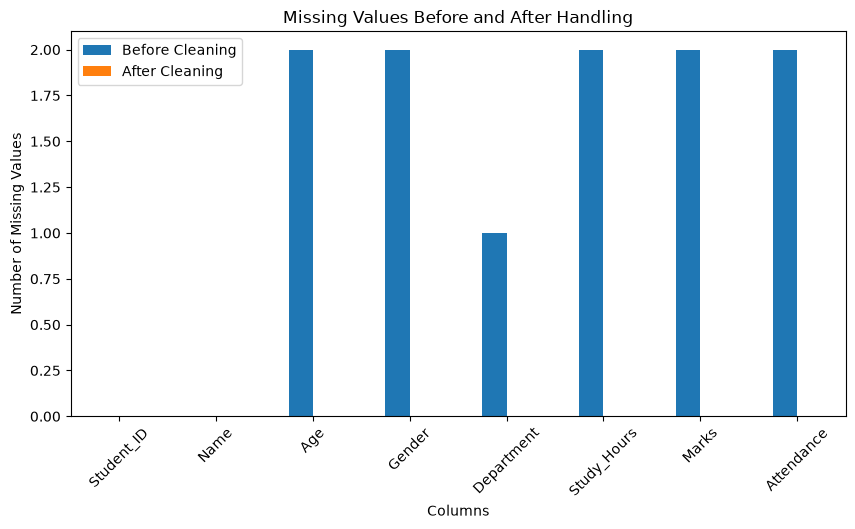

In [20]:
before = df.isnull().sum()
after = clean_df.isnull().sum()

comparison = pd.DataFrame({
    "Before Cleaning": before,
    "After Cleaning": after
})

comparison.plot(kind="bar", figsize=(10, 5))

plt.title("Missing Values Before and After Handling")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.show()

## 20. Final Data Validation

After handling missing values, we should check whether any missing values remain.

We should also check:
- Dataset shape.
- Missing value count.
- Duplicate records.
- Data types.

In [21]:
print("Final dataset information:")
clean_df.info()

print("\nTotal missing values:", clean_df.isnull().sum().sum())

print("\nDuplicate records:", clean_df.duplicated().sum())

print("\nFinal dataset shape:", clean_df.shape)

display(clean_df.head())

Final dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Student_ID   10 non-null     int64  
 1   Name         10 non-null     str    
 2   Age          10 non-null     float64
 3   Gender       10 non-null     str    
 4   Department   10 non-null     str    
 5   Study_Hours  10 non-null     float64
 6   Marks        10 non-null     float64
 7   Attendance   10 non-null     float64
dtypes: float64(4), int64(1), str(3)
memory usage: 895.0 bytes

Total missing values: 0

Duplicate records: 0

Final dataset shape: (10, 8)


,Student_ID,Name,Age,Gender,Department,Study_Hours,Marks,Attendance
0,101,Asha,20.0,Female,AI,3.0,75.0,90.0
1,102,Rahul,21.0,Male,CS,5.0,82.0,85.0
2,103,Priya,21.5,Female,AI,4.0,76.5,88.0
3,104,Kiran,22.0,Female,EC,4.0,68.0,75.0
4,105,Sneha,23.0,Female,Unknown,6.0,90.0,86.5


## 21. Avoiding Data Leakage During Imputation

Data leakage happens when information from the test dataset is used during model training.

For example, calculating the mean or median using the complete dataset before splitting it into training and testing data can cause data leakage.

### Correct approach

1. Split the dataset into training and testing datasets.
2. Calculate the imputation value using only the training dataset.
3. Use the same imputation value to fill missing values in the testing dataset.

This ensures that the test data does not influence the training process.

In Scikit-learn, fit the imputer on training data and use transform() on testing data.

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

sample = df[["Age", "Marks"]].copy()

X_train, X_test = train_test_split(
    sample,
    test_size=0.2,
    random_state=42
)

imputer = SimpleImputer(strategy="median")

# Learn median values from training data only
X_train_imputed = imputer.fit_transform(X_train)

# Apply the same learned values to test data
X_test_imputed = imputer.transform(X_test)

print("Training data after imputation:")
print(X_train_imputed)

print("\nTesting data after imputation:")
print(X_test_imputed)

Training data after imputation:
[[21.5 55. ]
 [20.  75. ]
 [24.  73.5]
 [21.5 73.5]
 [20.  72. ]
 [23.  90. ]
 [22.  68. ]
 [21.  78. ]]

Testing data after imputation:
[[22. 85.]
 [21. 82.]]


## 22. Data Cleaning Decision Documentation

| Column | Problem | Technique | Reason |
|---|---|---|---|
| Age | Missing numerical values | Median | Less affected by outliers |
| Gender | Missing categorical values | Mode | Uses the most frequent category |
| Department | Missing categorical values | Constant | Keeps missing information as Unknown |
| Study_Hours | Missing numerical values | Median | Fills missing values with a typical value |
| Marks | Missing numerical values | Median | Suitable for numerical data |
| Attendance | Missing numerical values | Median | Fills missing attendance records |

### Result

- Missing values were identified.
- Missing value percentages were calculated.
- Different imputation techniques were implemented.
- The cleaned dataset was created.
- The final dataset was checked for missing values.

### Impact

Handling missing values improves data completeness and prepares the dataset for further analysis and machine learning.

The imputation method should always be selected based on the dataset and problem requirements.

## 23. Conclusion

In this notebook, I learned how to identify, analyze, and handle missing values using Python, Pandas, NumPy, and Scikit-learn.

I understood the three types of missing values:

- MCAR – Missing Completely At Random
- MAR – Missing At Random
- MNAR – Missing Not At Random

I also implemented different missing value handling techniques:

- Removing missing values
- Mean imputation
- Median imputation
- Mode imputation
- Constant value imputation
- Forward fill and backward fill
- Interpolation
- Group-based imputation
- KNN imputation
- Iterative imputation

Finally, I compared the dataset before and after handling missing values and learned how to avoid data leakage during imputation.

The cleaned dataset is now ready for further data preprocessing steps.

## 24. Mini Assessment

### Conceptual Questions

1. What are missing values?
2. What is the difference between MCAR, MAR, and MNAR?
3. Which Pandas function is used to identify missing values?
4. How do we calculate the percentage of missing values?
5. What is the difference between mean and median imputation?
6. When do we use mode imputation?
7. What is forward fill?
8. What is backward fill?
9. What is KNN imputation?
10. What is data leakage during imputation?

### Coding Exercises

1. Create a DataFrame with missing values in three columns.
2. Identify missing values using isnull().
3. Calculate the missing value percentage for each column.
4. Fill numerical missing values using median.
5. Fill categorical missing values using mode.
6. Replace missing values with "Unknown".
7. Apply forward fill and backward fill.
8. Apply KNNImputer to numerical columns.
9. Compare missing values before and after cleaning.
10. Check whether any missing values remain.